# Capacity Scaling & Hyperparameter Optimization Analysis

This analytical review quantifies the empirical performance gains achieved by optimizing the training hyperparameters (learning rate, batch size bounds, and dynamic epoch termination via early stopping) of the definitive **FiLM Multimodal Fusion Operator** at a fixed bottleneck representation limit ($m=64$) under the **Trainable Sequential Linear Projection** head.

### Experimental Phases
- **Init Configuration (Baseline)**: Model trained using standard default parameters ($BS=32$, $\eta=1e-4$) bounded dynamically by validation convergence.
- **Optimized Configuration (Tuned)**: Optimal parameter trajectories discovered across exhaustive Optuna parameter sweeps prioritized for listwise ranking alignment.

---


=== HYPERPARAMETER OPTIMIZATION MATRIX ===


,Optimization State,Dev nDCG (%),Test nDCG (%),Cross-Lingual nDCG (%),Dev Top-1 Exact (%),Test Top-1 Exact (%),Cross-Lingual Top-1 Exact (%),Avg Optimal Epoch
0,Init Configuration (FiLM),77.47,80.02,72.24,33.60,35.71,16.81,6.0
1,Optimized Configuration (FiLM),78.30,80.34,71.52,34.38,35.00,15.80,3.6


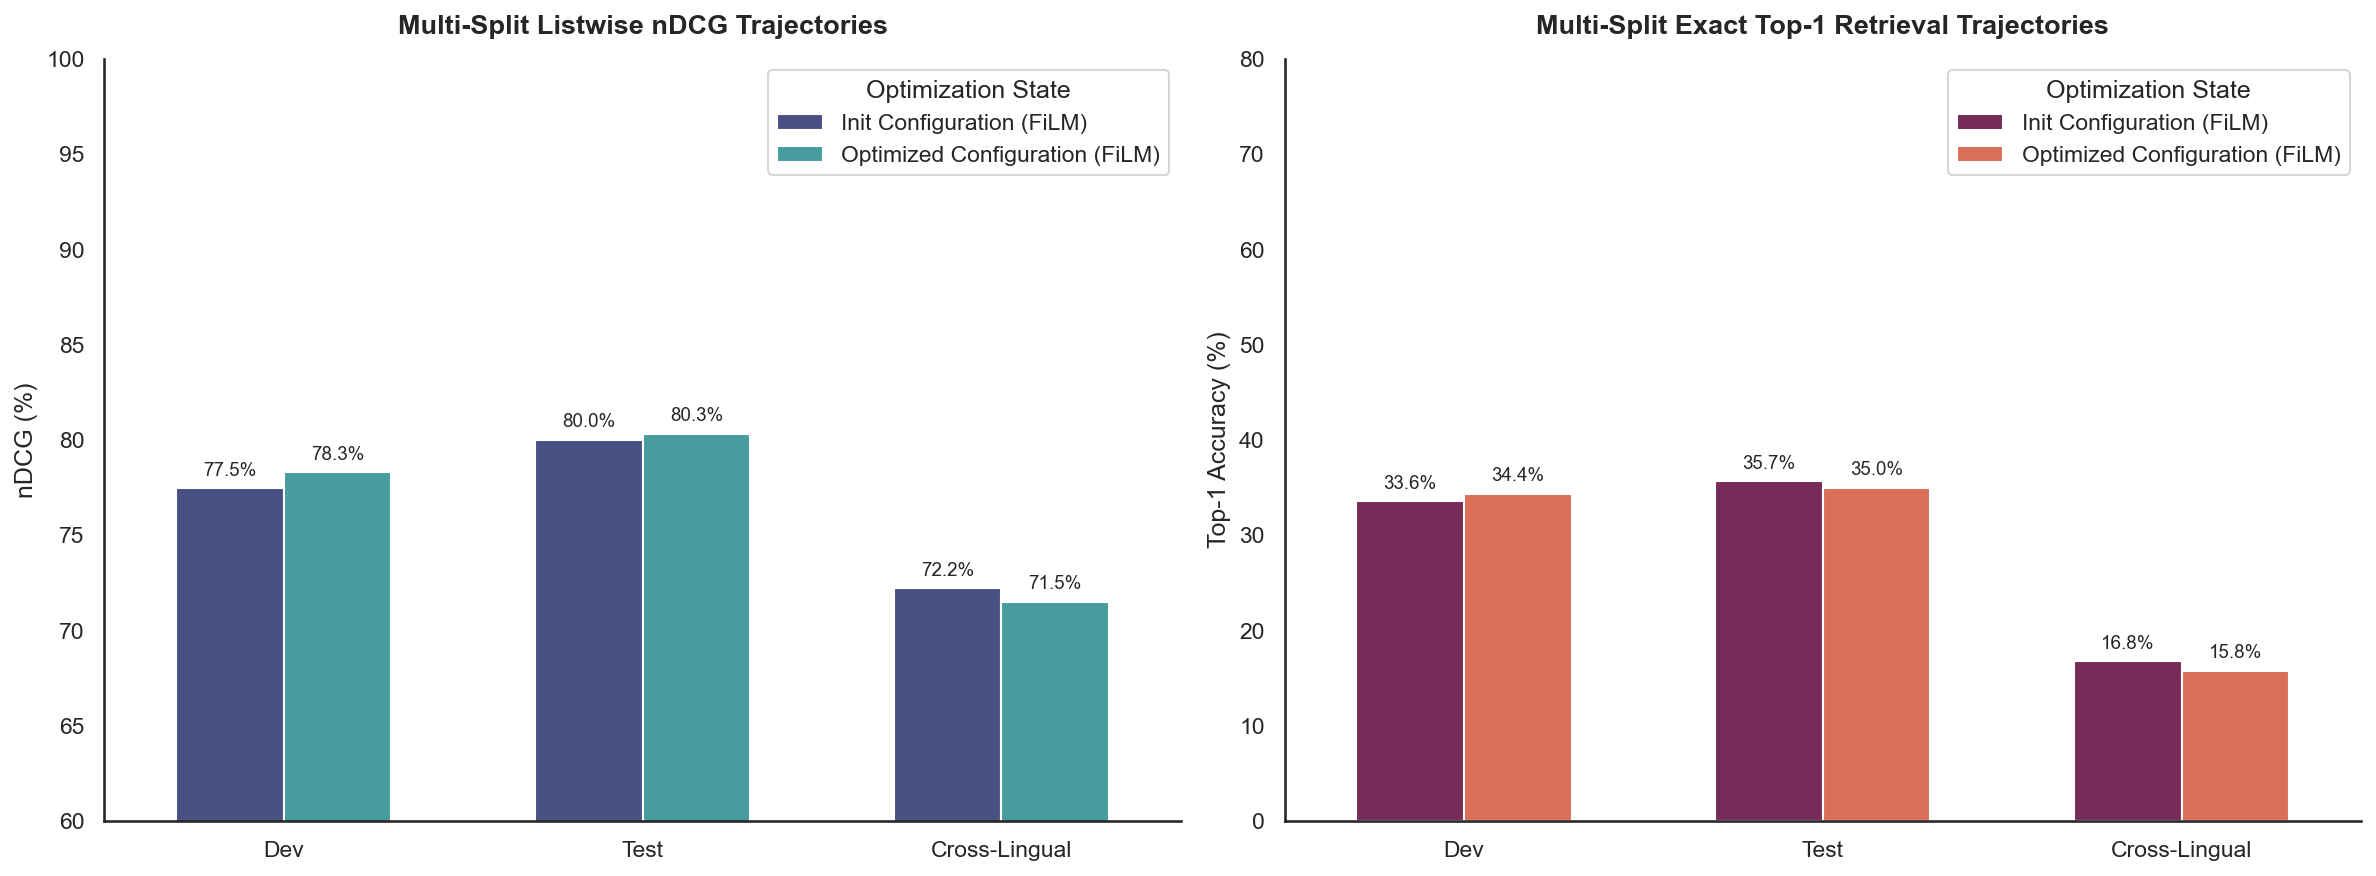

In [10]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.style.use('default')
sns.set_theme(style="white", palette="muted")
plt.rcParams['figure.dpi'] = 150

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path(".")
paths = {
    'Init Configuration (FiLM)': base_dir / 'baseline/summary.json',
    'Optimized Configuration (FiLM)': base_dir / 'final_model/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary and 'aggregate' in summary:
        data[name] = summary['aggregate'][0]

if len(data) == 2:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Optimization State': name,
            'Dev nDCG (%)': agg['best_dev']['ndcg'] * 100.0,
            'Test nDCG (%)': agg['test']['ndcg'] * 100.0,
            'Cross-Lingual nDCG (%)': agg['xeval']['ndcg'] * 100.0,
            'Dev Top-1 Exact (%)': agg['best_dev']['top1'] * 100.0,
            'Test Top-1 Exact (%)': agg['test']['top1'] * 100.0,
            'Cross-Lingual Top-1 Exact (%)': agg['xeval']['top1'] * 100.0,
            'Avg Optimal Epoch': agg.get('best_epoch', 50.0)
        })
        
    df = pd.DataFrame(rows)
    print("\n=== HYPERPARAMETER OPTIMIZATION MATRIX ===")
    display(df.round(2))
    
    # Visual trajectory rendering
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left panel: Listwise multi-split ranking metrics
    melted_ndcg = df.melt(id_vars=["Optimization State"], 
                          value_vars=["Dev nDCG (%)", "Test nDCG (%)", "Cross-Lingual nDCG (%)"],
                          var_name="Split", value_name="nDCG Score (%)")
    # Eksen etiketlerini daha estetik görünmesi için sadeleştiriyoruz
    melted_ndcg['Split'] = melted_ndcg['Split'].str.replace(" nDCG (%)", "", regex=False)
    
    sns.barplot(data=melted_ndcg, x="Split", y="nDCG Score (%)", hue="Optimization State", 
                palette="mako", width=0.6, ax=axes[0])
    axes[0].set_title("Multi-Split Listwise nDCG Trajectories", fontsize=13, pad=12, fontweight='bold')
    axes[0].set_ylabel("nDCG (%)")
    axes[0].set_xlabel("")
    axes[0].set_ylim(60, 100)
    
    for p in axes[0].patches:
        height = p.get_height()
        if height > 0:
            axes[0].annotate(f'{height:.1f}%', (p.get_x() + p.get_width() / 2., height),
                             ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontsize=9)
                             
    # Right panel: Multi-split exact Top-1 retrieval accuracy metrics
    melted_top1 = df.melt(id_vars=["Optimization State"], 
                          value_vars=["Dev Top-1 Exact (%)", "Test Top-1 Exact (%)", "Cross-Lingual Top-1 Exact (%)"],
                          var_name="Split", value_name="Top-1 Score (%)")
    # Eksen etiketlerini daha estetik görünmesi için sadeleştiriyoruz
    melted_top1['Split'] = melted_top1['Split'].str.replace(" Top-1 Exact (%)", "", regex=False)
    
    sns.barplot(data=melted_top1, x="Split", y="Top-1 Score (%)", hue="Optimization State", 
                palette="rocket", width=0.6, ax=axes[1])
    axes[1].set_title("Multi-Split Exact Top-1 Retrieval Trajectories", fontsize=13, pad=12, fontweight='bold')
    axes[1].set_ylabel("Top-1 Accuracy (%)")
    axes[1].set_xlabel("")
    axes[1].set_ylim(0, 80)
    
    for p in axes[1].patches:
        height = p.get_height()
        if height > 0:
            axes[1].annotate(f'{height:.1f}%', (p.get_x() + p.get_width() / 2., height),
                             ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontsize=9)
                             
    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("Optimization artifacts not detected. Please execute 'python ranking_experiments/hyperparam_tuning/run.py' to generate deterministic baseline and tuning payloads.")